CONTROLLA I VALORI DEI COEFFS CHE HO SUL QUADERNO, DEVONO CORRISPONDERE

In [178]:
'''Esercizio B.1 
Produrre, utilizzando la formula semiempirica di massa e tramite calcolatore, il grafico delle masse atomiche in funzione di Z, selezionando un valore di A a vostra scelta.
Ripetere l'operazione per il valore A + 1.
Confrontare la previsione del modello con i dati sperimentali reperibili sul web.
'''

"Esercizio B.1 \nProdurre, utilizzando la formula semiempirica di massa e tramite calcolatore, il grafico delle masse atomiche in funzione di Z, selezionando un valore di A a vostra scelta.\nRipetere l'operazione per il valore A + 1.\nConfrontare la previsione del modello con i dati sperimentali reperibili sul web.\n"

In [179]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Costanti
c = 1 # unità naturali
mp = 938.272089 # MeV 
mn = 939.565422 # MeV 
me = 0.51099895 # MeV
u = 931.5 # Mev

# Coefficienti
av, a_s, ac, aa, ap = 15.75, 17.8, 0.71, 23.7, 11.0

In [ ]:
### Eccessi di massa dal databse: https://www.nndc.bnl.gov/walletcards/search.html
nomi = np.array(["Pt", "Au", "Hg", "Tl", "Pb", "Bi", "Po", "At", "Rn", "Fr"])

eccessi_206 = np.array([
    -9200.0,
    -14200.0,
    -20946.0,
    -22253.3,
    -23785.5,
    -20028.0,
    -18189.0,
    -12439.0,
    -9133.0,
    -1250.0
])   # keV, Z in [78, 87]

eccessi_207 = np.array([
    -4140,
    -10640,
    -16487.446,
    -21034.436,
    -22451.968,
    -20054.554,
    -17145.7,
    -13227.482,
    -8634.742,
    -2849.021,
])  # keV


def M_from_database(Delta, A):
    '''Nel databse trovo Delta, l'eccesso di massa'''
    return Delta + A *u

db_206 = M_from_database(eccessi_206*1e-3, 206)   
db_207 = M_from_database(eccessi_207*1e-3, 207)
# alla -3, perchè il databse li dà in keV, li devo passare in MeV

In [ ]:
# Formule

def segno_delta(N, Z):
    result = []

    for n, z in zip(N, Z):
        if n % 2 == 0 and z % 2 == 0:
            result.append(1)
        elif n % 2 == 1 and z % 2 == 1:
            result.append(-1)
        else:
            result.append(0)

    return np.array(result)

    
def B(A,Z, segno):
    N = A-Z
    if segno==None:
        segno = segno_delta(N, Z)
        
    return av*A  \
        - a_s * A**(2/3) \
        - ac *Z*(Z-1)/A**(1/3) \
        - aa *(N-Z)**2/A \
        + segno * ap/A**(1/2)


def M(A,Z, segno=None):
    '''Massa atomica, trascurando Be, l'energia di legame degli elettroni'''  
    N = A-Z
    return Z * (mp + me) \
        + N * mn  \
        -B(A,Z,segno)/(c**2)


In [183]:
# Cosa plottare

A = 206
Z = np.linspace(78, 87, 10) # gli atomi
z = np.linspace(78, 87, 100) # le parabole

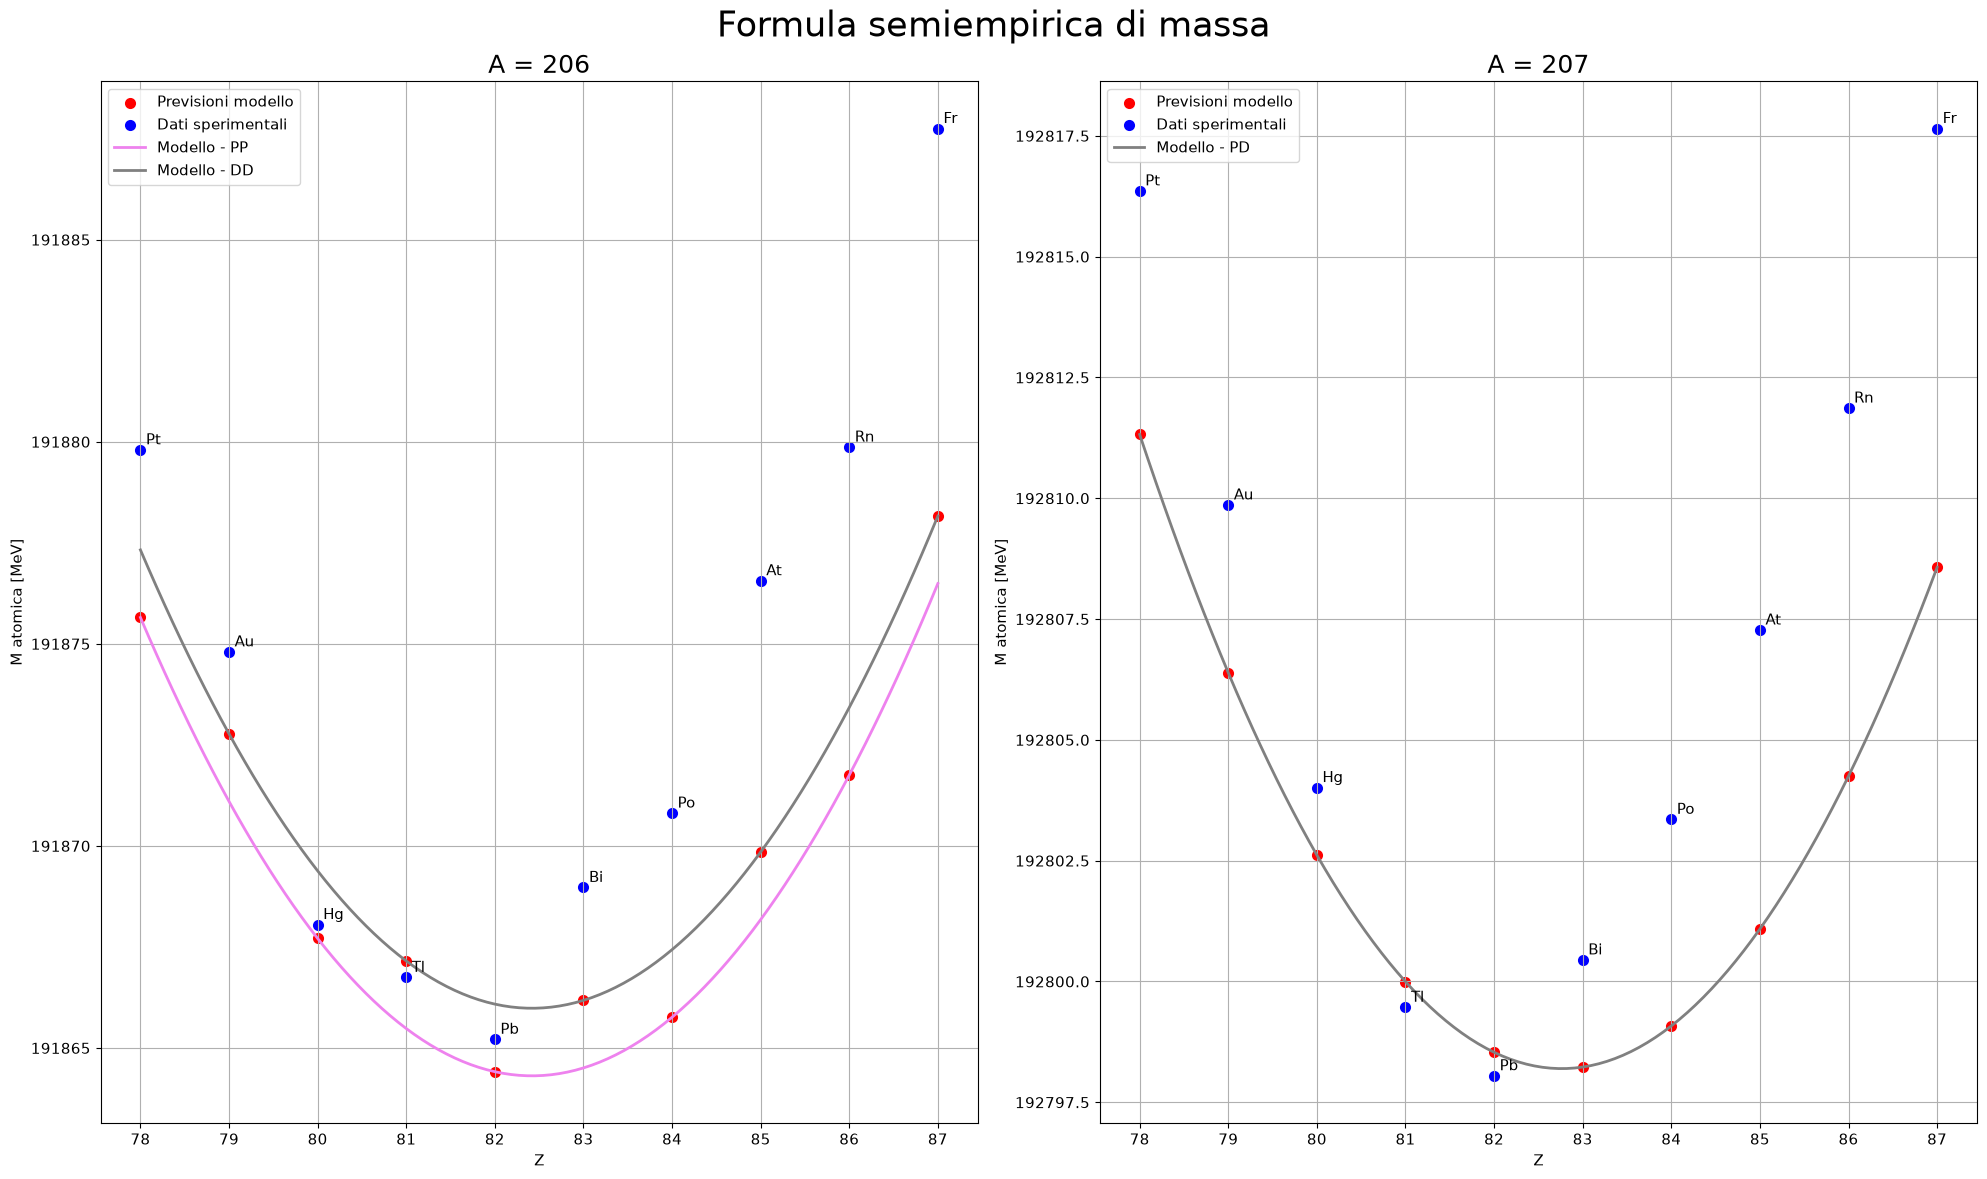

In [184]:
# Plot
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(20, 12))

fig.suptitle( "Formula semiempirica di massa", fontsize=25)

ax1.scatter(Z, M(A,Z), linewidth=2, label="Previsioni modello", color='red')
ax1.scatter(Z, db_206, linewidth=2, label="Dati sperimentali", color='blue')
ax1.plot(z, M(A,z, segno=1), linewidth=2, color = 'violet', label="Modello - PP")  # completa la linea, magari tratteggiata???
ax1.plot(z, M(A,z, segno=-1), linewidth=2, color = 'gray', label="Modello - DD")  # completa la linea, magari tratteggiata???
ax1.set_xlabel("Z")
ax1.set_ylabel("M atomica [MeV]")
ax1.grid(True, which="both")
ax1.set_xticks(Z)
ax1.set_title(f"A = {A}", fontsize=18)
ax1.legend()

ax2.scatter(Z, M(A+1,Z), linewidth=2, label="Previsioni modello", color='red')
ax2.scatter(Z, db_207, linewidth=2, label="Dati sperimentali", color='blue')
ax2.plot(z, M(A+1,z), linewidth=2, color = 'gray', label="Modello - PD")  # completa la linea, magari tratteggiata???
ax2.set_xlabel("Z")
ax2.set_ylabel("M atomica [MeV]")
ax2.grid(True, which="both")
ax2.set_xticks(Z)
ax2.set_title(f"A = {A+1}", fontsize=18)
ax2.legend()

# Nomi degli elementi
for x, y, name in zip(Z, db_206, nomi):
    ax1.annotate(name, (x, y), xytext=(4, 4),
                textcoords="offset points")
for x, y, name in zip(Z, db_207, nomi):
    ax2.annotate(name, (x, y), xytext=(4, 4),
                textcoords="offset points")

fig.tight_layout()
plt.show()

perchè dice che il bismuto è il più stabile?  
perchè ho omesso Be, l'energia di legame degli elettroni  
che deve essere legata all'elettronegatività dell'atomo  
il nucleo c'è la più ..., perchè ha gli orbitali completi, mentre il bismuto....  
anche se il biscmuto ha più elettroni, quindi ne devo estrarre uno in più???

Be deve dipendere da come sono riempiti i nunmeri elettronici, non può essere costante per tutti  

tellurio decade con beta-, bismuto con beta+ ->  verso il piombo  
lo dice il database, e lo conferma il grafico    

**Spiegazione**

nella fissione nucleare, l'uranio non si divide in due atomi uguali, ma in uno grande e uno piccolo (vedi grafico)  
e questo non è spiegato dal modello a goccia, ma da quello a guscio  
quindi, anche qui deve esserci lo stesso problema  